# P17 — Composição celular pelo método mais recente do espacial (`forest_composicao`)

**Pergunta.** A proporção de cada tipo CD4⁺ muda com o estímulo (NS × ML) ou entre os grupos
clínicos?

**Método:** o de `/mnt/SATA/spatialPaper/src/forest_composicao/` (`composicao.py`, `forest.py`,
`run_analise.py`), a versão que substituiu os scripts R usados no P15. Os módulos estão copiados
sem mudança de cálculo em [functions/composicao.py](../../functions/composicao.py) e
[functions/forest_composicao.py](../../functions/forest_composicao.py):

1. proporção de cada tipo **por amostra** (a biblioteca, nunca a célula);
2. **CLR com pseudocontagem na escala de contagem**, `(k + 0,5) / (N + 0,5 K)`, e não 1e-6 na
   proporção;
3. **filtro de prevalência**: o tipo entra se aparece em ≥ 1 % das células de ≥ 3 amostras de cada
   grupo;
4. `lm(CLR ~ grupo + covariáveis)` por tipo; para um modelo aditivo, o contraste do `emmeans` é o
   coeficiente do grupo;
5. **BH entre os tipos testados**; o critério é o FDR;
6. **um forest por contraste**, com o painel dos dados brutos ao lado (1 ponto = 1 amostra) e a
   coluna de p e FDR; todos os modelos são sempre calculados e comparados.

**Rótulos:** a anotação do P09 sem contaminante nem baixa qualidade (30.933 células):
`anotacao` (10 tipos) e `grupo` (5 categorias).

## Adaptação ao desenho do single-cell

| | espacial | aqui | por quê |
| --- | --- | --- | --- |
| amostra | 28 cortes = 28 pacientes | 14 bibliotecas = 7 pacientes × NS/ML | cada paciente tem as duas condições |
| contraste principal | FB × UB, todas as amostras | **ML × NS, as 14 bibliotecas, com o paciente no modelo** | o estímulo é o único contraste dentro do paciente, e o único com 7 pares |
| covariável técnica | `study` (profundidade 5,5× entre estudos) | `paciente` (absorve tudo que é do paciente e da captura) | com o paciente no modelo, o `study` não tem análogo |
| covariável de precisão | `%MT` da amostra (não difere entre FB e UB) | `%MT` da biblioteca (não difere entre NS e ML, seção 1) | mesma regra |
| `stage` (1 amostra early) | sensibilidade | profundidade (UMI mediana): sensibilidade | a profundidade é menor em ML (p = 0,047): ajustar por ela pode tirar efeito real |
| grupo clínico | — | **doentes (PB + MB + NP) × controles** e **PB × controles**, **um ponto por paciente** (média do CLR das suas duas bibliotecas) | usar as 14 bibliotecas contaria cada paciente duas vezes; com o desenho balanceado, a média por paciente é o teste entre pacientes de um modelo misto |
| filtro de prevalência | ≥ 3 amostras de cada grupo | igual; no PB (2 pacientes), todas as do grupo | com 2 pacientes, "≥ 3" excluiria tudo |
| rótulo das linhas | id do nicho + 3 marcadores | nome do tipo + 3 marcadores | os tipos já estão anotados |

A análise por condição (PB × controle só em NS ou só em ML), que é a pergunta dos scripts R, entra
como sensibilidade, com a mesma pseudocontagem, como sugere o README do espacial.

O código novo do contraste entre pacientes está em [functions/composicao_sc.py](../../functions/composicao_sc.py).

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest, mannwhitneyu, wilcoxon

from functions import config, io, issues, plotting
from functions import composicao as CP
from functions import composicao_sc as CS
from functions import forest_composicao as FR

NB = "analises_previas/P17_composicao_forest"
log = issues.IssueLog(NB)
pd.set_option("display.width", 230)
GRANS = ["anotacao", "grupo"]
plt.rcParams["savefig.bbox"] = "tight"   # como o run_analise.py (bbox_inches="tight"): rótulos longos não cortam

COR_EST = {"nao estimulado": plotting.STIMULATION_COLORS["nao_estimulado"],
           "estimulado": plotting.STIMULATION_COLORS["estimulado"]}
ROT_EST = {"nao estimulado": "não estimulado (NS)", "estimulado": "estimulado (ML)"}
COR_CLI = {"controle": plotting.CLASSIFICATION_COLORS["controle"], "PB": plotting.CLASSIFICATION_COLORS["PB"],
           "hanseniase": plotting.CLASSIFICATION_COLORS["PB"]}
ROT_CLI = {"controle": "controle", "PB": "paucibacilar (PB)", "hanseniase": "hanseníase (PB + MB + NP)"}

## 1. Células e desenho no nível da biblioteca

In [2]:
a = ad.read_h5ad(config.DATA_OUT / "analises_previas/P13_objeto_final" / "reseq_final.h5ad")
a = a[~a.obs["grupo"].isin(["contaminante", "baixa qualidade"])].copy()
o = a.obs
cel = o[["library_id", "patient", "estimulo", "anotacao", "grupo"]].astype(str).copy()
cel["classificacao"] = cel["patient"].map(config.PATIENT_CLASSIFICATION)
cel["doenca"] = np.where(cel["classificacao"] == "controle", "controle", "hanseniase")
print(f"{a.n_obs:,} células CD4⁺ · {cel.library_id.nunique()} bibliotecas · {cel.patient.nunique()} pacientes".replace(",", "."))

smp = o.groupby("library_id", observed=True).agg(
    patient=("patient", "first"), estimulo=("estimulo", "first"),
    pct_mt=("pct_counts_mt", "median"), umi=("total_counts", "median"), n=("patient", "size"))
smp["patient"] = smp["patient"].astype(str); smp["estimulo"] = smp["estimulo"].astype(str)
smp["classificacao"] = smp["patient"].map(config.PATIENT_CLASSIFICATION)
smp["log_umi"] = np.log10(smp["umi"])
io.save_table(smp.round(3), NB, "desenho_amostras", description="Desenho por biblioteca: paciente, estímulo, %MT e UMI medianos")
display(smp.sort_values(["classificacao", "patient", "estimulo"]).round(2))

30.933 células CD4⁺ · 14 bibliotecas · 7 pacientes


,patient,estimulo,pct_mt,umi,n,classificacao,log_umi
library_id,,,,,,,
MB34_ML,MB34,estimulado,0.59,11399.0,913,MB,4.06
MB34_NS,MB34,nao estimulado,1.54,14556.0,1922,MB,4.16
HNP44_ML,HNP44,estimulado,2.32,14551.0,1846,NP,4.16
HNP44_NS,HNP44,nao estimulado,1.68,18782.0,95,NP,4.27
PB20_ML,PB20,estimulado,1.41,10187.5,740,PB,4.01
PB20_NS,PB20,nao estimulado,1.04,9247.5,558,PB,3.97
PB21_ML,PB21,estimulado,3.98,8512.0,9281,PB,3.93
PB21_NS,PB21,nao estimulado,3.69,9587.0,3485,PB,3.98
CTH92_ML,CTH92,estimulado,2.50,4988.0,1231,controle,3.70


**As covariáveis.** Como no espacial, uma covariável técnica só entra como "de precisão" se não
difere entre os grupos comparados.

In [3]:
ns_ = smp[smp.estimulo == "nao estimulado"].set_index("patient")
ml_ = smp[smp.estimulo == "estimulado"].set_index("patient").loc[ns_.index]
cov_check = []
for c in ["pct_mt", "umi"]:
    cov_check.append({"covariável": c, "contraste": "ML × NS (Wilcoxon pareado)",
                      "ML − NS mediano": float((ml_[c] - ns_[c]).median()), "p": wilcoxon(ml_[c], ns_[c]).pvalue})
    pm = smp.groupby("patient")[c].mean(); cl = pd.Series(config.PATIENT_CLASSIFICATION)[pm.index]
    for nome, alvo in [("hanseníase × controle", cl != "controle"), ("PB × controle", cl == "PB")]:
        ref = cl == "controle"
        cov_check.append({"covariável": c, "contraste": f"{nome} (Mann-Whitney, média do paciente)",
                          "ML − NS mediano": np.nan, "p": mannwhitneyu(pm[alvo], pm[ref]).pvalue})
cov_check = pd.DataFrame(cov_check)
io.save_table(cov_check, NB, "covariaveis", index=False, description="%MT e UMI contra cada contraste")
display(cov_check.round(3))

,covariável,contraste,ML − NS mediano,p
0,pct_mt,ML × NS (Wilcoxon pareado),0.175,0.688
1,pct_mt,"hanseníase × controle (Mann-Whitney, média do ...",NaN,0.400
2,pct_mt,"PB × controle (Mann-Whitney, média do paciente)",NaN,1.000
3,umi,ML × NS (Wilcoxon pareado),-3157.000,0.047
4,umi,"hanseníase × controle (Mann-Whitney, média do ...",NaN,0.229
5,umi,"PB × controle (Mann-Whitney, média do paciente)",NaN,0.800


O %MT não difere em nenhum contraste e entra como covariável de precisão. A profundidade é menor em
ML (5 de 7 pacientes): é associada ao estímulo, então fica só como sensibilidade (o mesmo papel do
`stage` no espacial).

## 2. Rótulos das linhas: 3 marcadores por tipo

Como em `run_analise.marcadores_por_cluster`: Wilcoxon do scanpy na matriz lognormalizada (`X`).
Ficam de fora dos rótulos os genes ribossomais (RPL/RPS), mitocondriais e sem símbolo.

In [4]:
rotulos = {}
for gran in GRANS:
    b = a.copy()
    b.var_names = b.var["gene_symbol"].astype(str).values if "gene_symbol" in b.var else b.var_names
    b.var_names_make_unique()
    b.obs[gran] = b.obs[gran].astype(str).astype("category")
    sc.tl.rank_genes_groups(b, gran, method="wilcoxon", n_genes=30)
    nomes = pd.DataFrame(b.uns["rank_genes_groups"]["names"])
    # sem genes ribossomais, mitocondriais e sem símbolo (ENSG): não dizem nada sobre o tipo
    informativo = lambda s: s[~s.str.match(r"^(RP[LS]\d|MT-|ENSG)")].head(3)
    rotulos[gran] = {c: f"{c} · " + ", ".join(informativo(nomes[c])) for c in nomes.columns}
    del b
io.save_table(pd.DataFrame([(g, k, v) for g, d in rotulos.items() for k, v in d.items()],
                           columns=["granularidade", "tipo", "rotulo"]), NB, "marcadores", index=False,
              description="3 marcadores por tipo, para rotular as linhas dos forests")
for g in GRANS:
    print("\n".join(rotulos[g].values()), "\n")

CD4 Tcm · FTH1, NR3C1, PHACTR2
CD4 Tcm/Tfh · ANK3, SPON1, LIMS1
CD4 Tem GZMK⁺ · LYST, NUCB2, SESTD1
CD4 Th17 · IL7R, RORA, EML4
CD4 ativada · B2M, HLA-B, IL32
CD4 ativada (Th17) · IL4I1, LTB, TNFRSF4
CD4 citotóxica (Temra) · CCL5, NKG7, GNLY
CD4 naive · FHIT, TSHZ2, IGF1R
CD4 transição naive/Tcm · TPT1, FAU, EEF1A1
Treg · FOXP3, IKZF2, TIGIT 

CD4 ativada · B2M, IL32, HLA-B
CD4 citotóxica · CCL5, NKG7, GNLY
CD4 memória · FTH1, PHACTR2, IL7R
CD4 naive · FHIT, TSHZ2, IGF1R
Treg · FOXP3, IKZF2, TIGIT 



## 3. Estímulo: ML × NS, dentro do paciente

`CLR ~ estímulo + paciente + %MT` nas 14 bibliotecas (a figura). Os quatro modelos são sempre
calculados, como em `run_analise.py`.

In [5]:
MODELOS_EST = {
    "paciente_mt": ["patient", "pct_mt"],        # figura
    "paciente": ["patient"],
    "paciente_mt_umi": ["patient", "pct_mt", "log_umi"],
    "sem_paciente_mt": ["pct_mt"],               # ignora o pareamento
}
ORDEM_EST = ["estimulado", "nao estimulado"]     # contraste ML − NS: efeito > 0 = maior em ML

comps, filtros, est = {}, {}, {}
for gran in GRANS:
    comp = CP.build_composition(cel, gran, sample_col="library_id", group_col="estimulo",
                                covars=["patient", "classificacao", "doenca"], min_cells=30)
    for c in ["pct_mt", "log_umi"]:
        comp["meta"][c] = smp[c].reindex(comp["meta"].index).astype(float)
    filt = CP.filtro_prevalencia(comp, min_pac=3, min_frac=0.01)
    comps[gran], filtros[gran] = comp, filt
    io.save_table(filt["tabela"], NB, f"filtro_prevalencia_estimulo_{gran}", description=f"Filtro de prevalência, ML × NS ({gran})")
    print(f"\n=== {gran}: {len(filt['testaveis'])} de {len(comp['cell_cols'])} tipos testáveis; "
          f"fora: {filt['excluidos']}")
    for nome, covs in MODELOS_EST.items():
        res = CP.run_contrast(comp, filt["testaveis"], ordem_grupos=ORDEM_EST, covars=covs, verbose=False)
        est[(gran, nome)] = res
        io.save_table(res, NB, f"estimulo_{gran}_{nome}", index=False,
                      description=f"CLR ~ estímulo + {' + '.join(covs)} ({gran}), contraste ML − NS")
    cmp = pd.DataFrame({n: est[(gran, n)].set_index("cell_population")["FDR"] for n in MODELOS_EST})
    cmp.insert(0, "efeito (figura)", est[(gran, "paciente_mt")].set_index("cell_population")["estimate"])
    cmp = cmp.sort_values("paciente_mt")
    io.save_table(cmp, NB, f"comparacao_modelos_estimulo_{gran}", description=f"FDR do ML − NS nos quatro modelos ({gran})")
    display(cmp.round(4))


=== anotacao: 8 de 10 tipos testáveis; fora: ['CD4 Tem GZMK⁺', 'CD4 ativada (Th17)']


,efeito (figura),paciente_mt,paciente,paciente_mt_umi,sem_paciente_mt
cell_population,,,,,
CD4 Th17,-0.4120,0.1417,0.0915,0.2709,0.4862
CD4 ativada,0.8136,0.1529,0.0915,0.2824,0.4231
Treg,0.1323,0.7079,0.5079,0.2824,0.7103
CD4 Tcm/Tfh,-0.0567,0.7822,0.9793,0.2709,0.9400
CD4 Tcm,-0.0691,0.7822,0.6218,0.8976,0.7103
CD4 citotóxica (Temra),-0.1107,0.7822,0.9793,0.2709,0.9400
CD4 naive,-0.0279,0.7822,0.9793,0.7534,0.9400
CD4 transição naive/Tcm,-0.2695,0.7822,0.6859,0.4791,0.7103



=== grupo: 5 de 5 tipos testáveis; fora: []


,efeito (figura),paciente_mt,paciente,paciente_mt_umi,sem_paciente_mt
cell_population,,,,,
CD4 ativada,0.8660,0.0302,0.0124,0.1150,0.0653
CD4 memória,-0.3123,0.1172,0.0549,0.3177,0.0653
CD4 naive,-0.2104,0.1172,0.0549,0.3177,0.3926
CD4 citotóxica,-0.2931,0.2188,0.1728,0.1150,0.4886
Treg,-0.0502,0.7308,0.5061,0.1719,0.6874


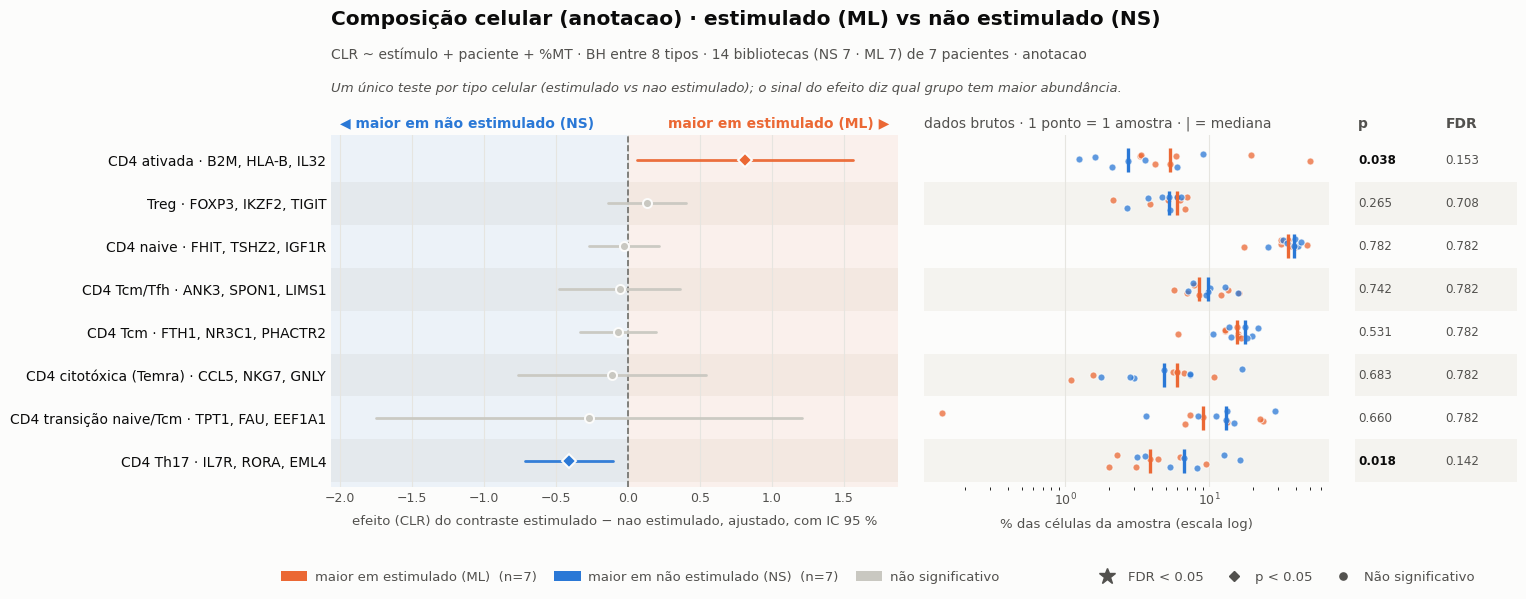

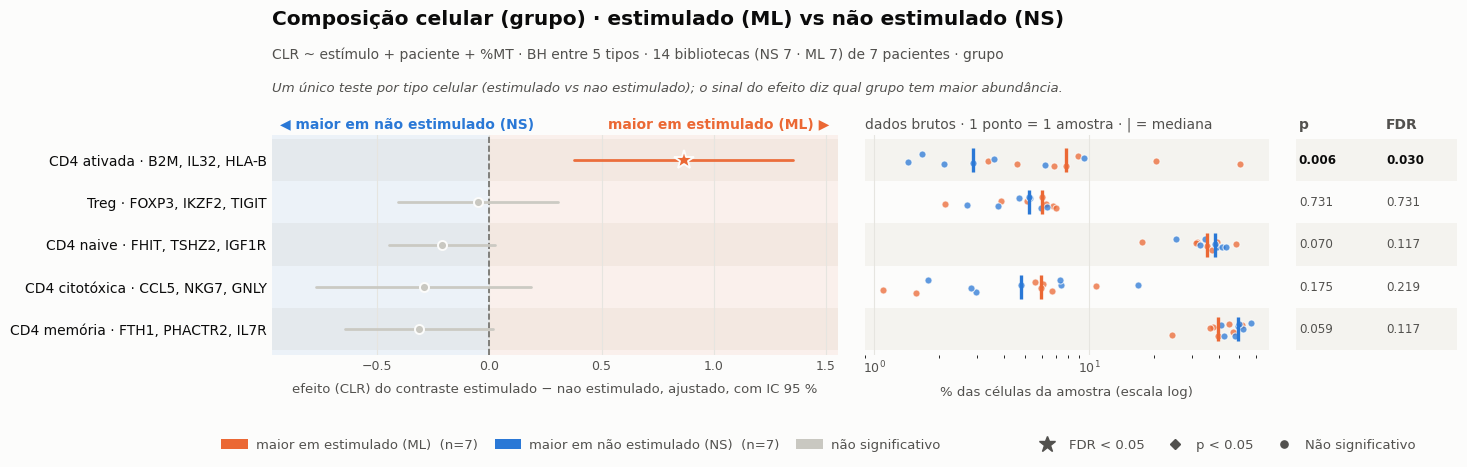

In [6]:
for gran in GRANS:
    res, comp = est[(gran, "paciente_mt")], comps[gran]
    sub = (f"CLR ~ estímulo + paciente + %MT · BH entre {len(res)} tipos · {res.attrs['n_amostras']} bibliotecas "
           f"(NS 7 · ML 7) de 7 pacientes · {gran}")
    fig, _ = FR.forest(res, comp, cores_grupo=COR_EST, rotulos=ROT_EST, subtitulo=sub, rotulos_linha=rotulos[gran],
                       titulo=f"Composição celular ({gran}) · estimulado (ML) vs não estimulado (NS)")
    plotting.savefig(fig, NB, f"forest_estimulo_{gran}", data=res, data_index=False,
                     description=f"Forest do contraste ML − NS, pareado por paciente ({gran})")
    plt.show()

**Consistência entre pacientes.** Quantos dos 7 pacientes vão no sentido do efeito? O teste do
sinal não depende de pseudocontagem nem de covariáveis (7 de 7 → p = 0,016; 6 de 7 → p = 0,125).

In [7]:
cons_all = {}
for gran in GRANS:
    comp = comps[gran]
    pm = comp["proportion"].join(comp["meta"][["estimulo", "patient"]])
    ns = pm[pm.estimulo == "nao estimulado"].set_index("patient")[comp["cell_cols"]]
    ml = pm[pm.estimulo == "estimulado"].set_index("patient")[comp["cell_cols"]].loc[ns.index]
    s, d = (ml > ns).sum(), (ml < ns).sum()
    cons = pd.DataFrame({"ML > NS": s, "ML < NS": d,
                         "p do sinal": [binomtest(int(max(x, y)), int(x + y)).pvalue for x, y in zip(s, d)],
                         "% mediana NS": 100 * ns.median(), "% mediana ML": 100 * ml.median(),
                         "FDR (figura)": est[(gran, "paciente_mt")].set_index("cell_population")["FDR"]}
                        ).sort_values("p do sinal")
    cons_all[gran] = cons
    io.save_table(cons, NB, f"consistencia_pacientes_{gran}", description=f"Pacientes em que ML > NS ({gran})")
    display(cons.round(3))

,ML > NS,ML < NS,p do sinal,% mediana NS,% mediana ML,FDR (figura)
CD4 Th17,0,7,0.016,6.708,3.899,0.142
CD4 ativada,6,1,0.125,2.723,5.309,0.153
CD4 ativada (Th17),6,1,0.125,0.151,1.216,NaN
CD4 Tcm/Tfh,2,5,0.453,9.777,8.437,0.782
CD4 citotóxica (Temra),2,5,0.453,4.826,5.946,0.782
Treg,5,2,0.453,5.263,6.013,0.708
CD4 Tem GZMK⁺,4,3,1.000,0.124,0.140,NaN
CD4 Tcm,3,4,1.000,17.640,15.493,0.782
CD4 naive,3,4,1.000,38.530,35.482,0.782
CD4 transição naive/Tcm,3,4,1.000,13.111,9.047,0.782


,ML > NS,ML < NS,p do sinal,% mediana NS,% mediana ML,FDR (figura)
CD4 ativada,7,0,0.016,2.874,7.801,0.030
CD4 memória,1,6,0.125,49.317,39.924,0.117
CD4 citotóxica,2,5,0.453,4.826,5.946,0.219
Treg,5,2,0.453,5.263,6.013,0.731
CD4 naive,3,4,1.000,38.530,35.482,0.117


## 4. Grupo clínico: um ponto por paciente

Cada paciente entra com a média do CLR das suas duas bibliotecas. Modelos:

* `media` (figura): os dois estímulos juntos;
* `media_mt`: + %MT médio do paciente;
* `so_NS` e `so_ML`: um estímulo por vez (a pergunta dos scripts R, com a pseudocontagem de contagem).

In [8]:
CONTRASTES = {"hanseniase_x_controle": ("doenca", ["hanseniase", "controle"]),
              "PB_x_controle": ("classificacao", ["PB", "controle"])}
cli = {}
for gran in GRANS:
    comp = comps[gran]
    for nome_c, (col, ordem) in CONTRASTES.items():
        cp_all = CS.comp_paciente(comp, "patient", col, ordem)
        filt = CS.filtro_prevalencia(cp_all, min_pac=3, min_frac=0.01)
        print(f"\n=== {gran} · {nome_c}: {len(cp_all['proportion'])} pacientes "
              f"({cp_all['meta'][col].value_counts().to_dict()}); filtro com ≥ {filt['min_pac']} por grupo: "
              f"{len(filt['testaveis'])} de {len(comp['cell_cols'])} tipos; fora: {filt['excluidos']}")
        modelos = {"media": (None, []), "media_mt": (None, ["pct_mt"]),
                   "so_NS": ("nao estimulado", []), "so_ML": ("estimulado", [])}
        for nome_m, (estim, covs) in modelos.items():
            cp = CS.comp_paciente(comp, "patient", col, ordem, estimulo=estim)
            res = CS.run_contrast_paciente(comp, cp, filt["testaveis"], ordem, covars=covs)
            cli[(gran, nome_c, nome_m)] = (res, cp)
            io.save_table(res, NB, f"{nome_c}_{gran}_{nome_m}", index=False,
                          description=f"{nome_c}, {gran}, {nome_m}: {res.attrs['modelo']}")
        cmp = pd.DataFrame({n: cli[(gran, nome_c, n)][0].set_index("cell_population")["FDR"] for n in modelos})
        cmp.insert(0, "efeito (figura)", cli[(gran, nome_c, "media")][0].set_index("cell_population")["estimate"])
        cmp.insert(1, "p (figura)", cli[(gran, nome_c, "media")][0].set_index("cell_population")["p_value"])
        cmp = cmp.sort_values("p (figura)")
        io.save_table(cmp, NB, f"comparacao_modelos_{nome_c}_{gran}", description=f"FDR nos quatro modelos ({nome_c}, {gran})")
        display(cmp.round(4))


=== anotacao · hanseniase_x_controle: 7 pacientes ({'hanseniase': 4, 'controle': 3}); filtro com ≥ 3 por grupo: 8 de 10 tipos; fora: ['CD4 Tem GZMK⁺', 'CD4 ativada (Th17)']


,efeito (figura),p (figura),media,media_mt,so_NS,so_ML
cell_population,,,,,,
CD4 naive,0.3620,0.0344,0.2495,0.4452,0.4725,0.1173
CD4 transição naive/Tcm,1.1579,0.0967,0.2495,0.4452,0.4725,0.2775
CD4 ativada,-1.0187,0.1106,0.2495,0.4452,0.5111,0.1589
Treg,0.3336,0.1248,0.2495,0.4452,0.5454,0.1173
CD4 Th17,-0.4233,0.2621,0.4194,0.5787,0.4725,0.6976
CD4 Tcm/Tfh,-0.2161,0.4096,0.5462,0.7041,0.9650,0.3637
CD4 citotóxica (Temra),-0.2409,0.6960,0.7089,0.7041,0.8907,0.3637
CD4 Tcm,0.0455,0.7089,0.7089,0.7041,0.4725,0.1173



=== anotacao · PB_x_controle: 5 pacientes ({'controle': 3, 'PB': 2}); filtro com ≥ 2 por grupo: 8 de 10 tipos; fora: ['CD4 Tem GZMK⁺', 'CD4 ativada (Th17)']


,efeito (figura),p (figura),media,media_mt,so_NS,so_ML
cell_population,,,,,,
CD4 naive,0.4730,0.0228,0.1825,0.5387,0.3823,0.1970
CD4 transição naive/Tcm,1.3117,0.1988,0.5584,0.5538,0.3823,0.4980
CD4 Th17,-0.5084,0.2622,0.5584,0.5538,0.3823,0.5928
CD4 ativada,-0.9174,0.3335,0.5584,0.5647,0.8988,0.4521
Treg,0.2829,0.3490,0.5584,0.5538,0.8988,0.3498
CD4 Tcm/Tfh,-0.2625,0.4504,0.6006,0.6356,0.3823,0.5625
CD4 citotóxica (Temra),-0.3895,0.5354,0.6118,0.5538,0.8988,0.4521
CD4 Tcm,0.0102,0.9403,0.9403,0.8528,0.3823,0.3498



=== grupo · hanseniase_x_controle: 7 pacientes ({'hanseniase': 4, 'controle': 3}); filtro com ≥ 3 por grupo: 5 de 5 tipos; fora: []


,efeito (figura),p (figura),media,media_mt,so_NS,so_ML
cell_population,,,,,,
CD4 naive,0.4435,0.0772,0.2665,0.3563,0.7377,0.1200
CD4 ativada,-0.8521,0.1100,0.2665,0.3563,0.7377,0.1200
Treg,0.4150,0.1599,0.2665,0.3563,0.8230,0.1200
CD4 memória,0.1530,0.4203,0.5253,0.7020,0.8230,0.2013
CD4 citotóxica,-0.1594,0.7761,0.7761,0.7020,0.8230,0.4126



=== grupo · PB_x_controle: 5 pacientes ({'controle': 3, 'PB': 2}); filtro com ≥ 2 por grupo: 5 de 5 tipos; fora: []


,efeito (figura),p (figura),media,media_mt,so_NS,so_ML
cell_population,,,,,,
CD4 naive,0.5333,0.0813,0.4067,0.4241,0.9945,0.2613
CD4 memória,0.1602,0.2541,0.4594,0.4241,0.9945,0.2723
CD4 ativada,-0.7076,0.3603,0.4594,0.4241,0.9945,0.2723
Treg,0.3432,0.3676,0.4594,0.4241,0.9945,0.2723
CD4 citotóxica,-0.3292,0.5881,0.5881,0.4241,0.9945,0.3348


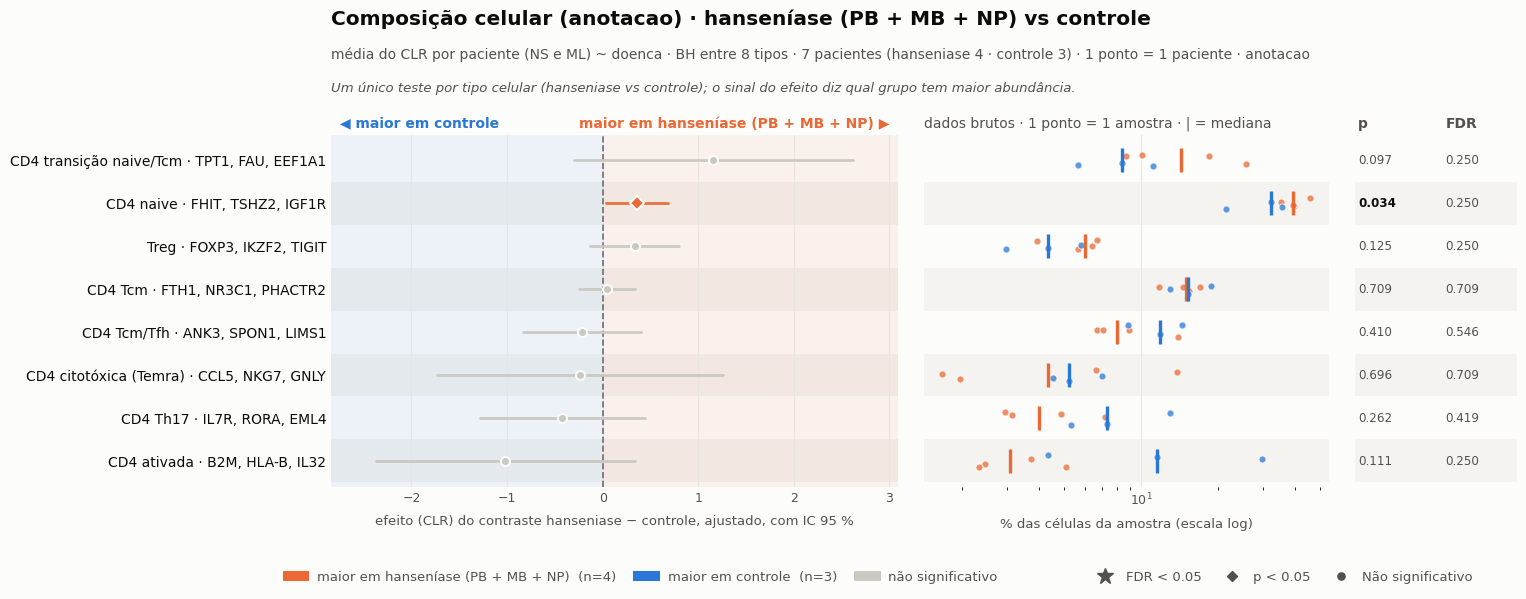

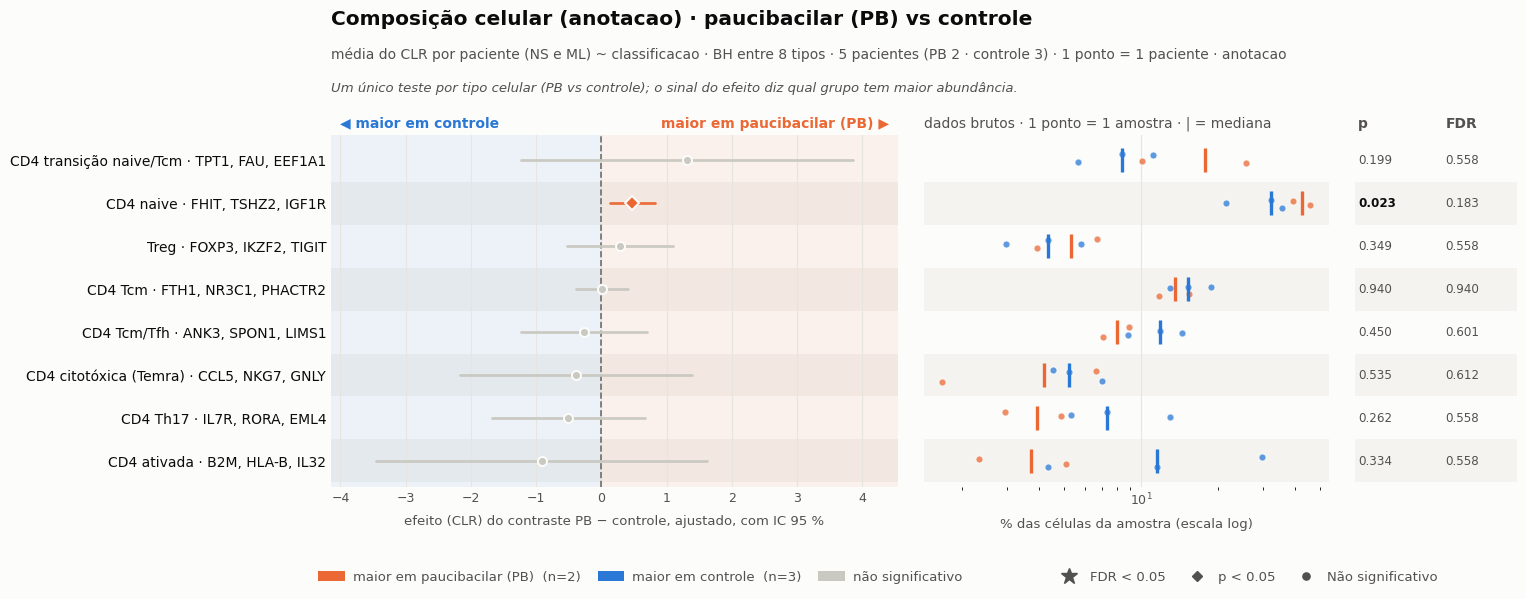

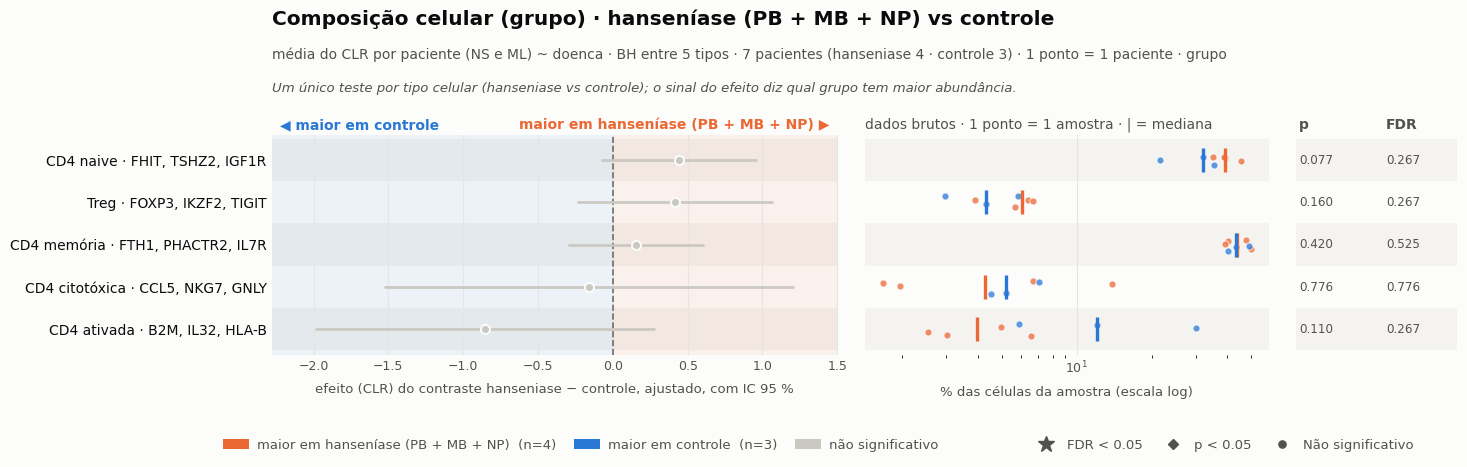

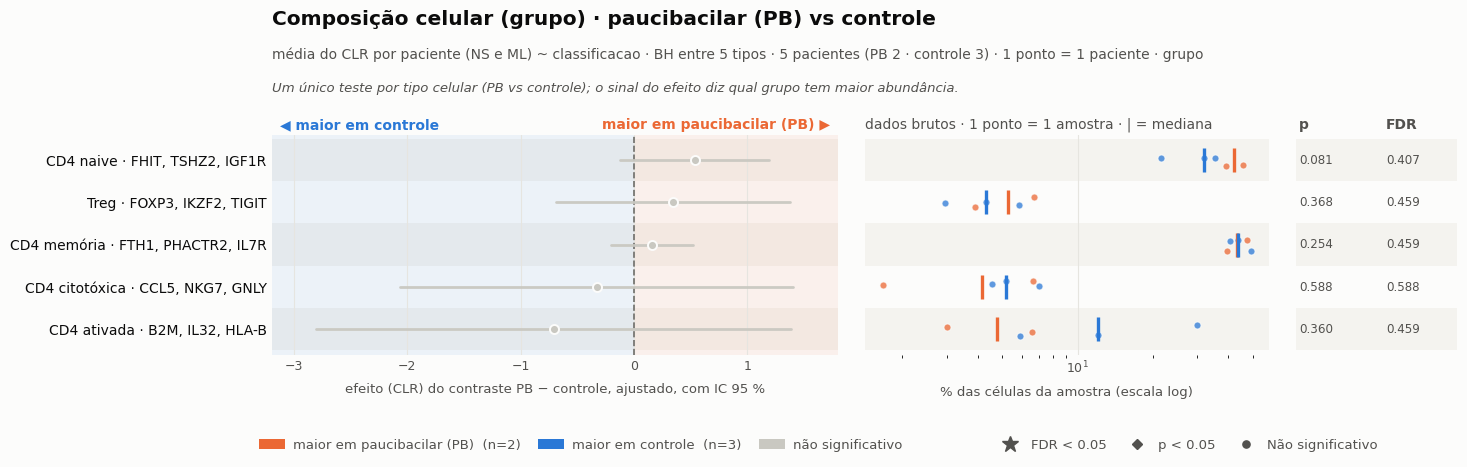

In [9]:
for gran in GRANS:
    for nome_c, (col, ordem) in CONTRASTES.items():
        res, cp = cli[(gran, nome_c, "media")]
        n = cp["meta"][col].value_counts()
        sub = (f"média do CLR por paciente (NS e ML) ~ {col} · BH entre {len(res)} tipos · {res.attrs['n_amostras']} pacientes "
               f"({ordem[0]} {n.get(ordem[0], 0)} · {ordem[1]} {n.get(ordem[1], 0)}) · 1 ponto = 1 paciente · {gran}")
        fig, _ = FR.forest(res, cp, cores_grupo=COR_CLI, rotulos=ROT_CLI, subtitulo=sub, rotulos_linha=rotulos[gran],
                           titulo=f"Composição celular ({gran}) · {ROT_CLI[ordem[0]]} vs {ROT_CLI[ordem[1]]}")
        plotting.savefig(fig, NB, f"forest_{nome_c}_{gran}", data=res, data_index=False,
                         description=f"Forest do contraste {nome_c} por paciente ({gran})")
        plt.show()

## 5. Interpretação

**Estímulo: o que muda é a fração de CD4 ativada.**

* No `grupo`, a **CD4 ativada sobe em 7 de 7 pacientes** (teste do sinal p = 0,016): +0,87 em CLR
  (cerca de ×2,4), mediana de 2,9 % para 7,8 %, **FDR 0,030** no modelo da figura (paciente + %MT)
  e 0,012 só com o paciente. A memória cai em 6 de 7 (49 % → 40 %; FDR 0,12 e 0,055).
* Na `anotacao`, o mesmo sinal fica abaixo do corte: **CD4 Th17 cai em 7 de 7** (6,7 % → 3,9 %;
  p = 0,018, FDR 0,14) e a CD4 ativada sobe (p = 0,038, FDR 0,15). Com 8 tipos testados e 5 graus
  de liberdade, o BH pesa mais que no `grupo`. A queda da Th17 é, ao menos em parte, Th17 que se
  ativa e passa para o cluster ativado (a "ativada (Th17)" sobe em 6 de 7, mas sai no filtro de
  prevalência por ser rara).
* **Treg não muda** (5,3 % → 6,0 %; FDR 0,71 a 0,73), como no P14 e no P15.

**Os quatro modelos.** O %MT não difere entre NS e ML (p = 0,69), então entra como covariável de
precisão, pela regra do espacial. Aqui ele não ajuda: com 14 bibliotecas, custa um grau de
liberdade (6 → 5) e explica pouca variância (CD4 ativada: FDR 0,012 sem ele, 0,030 com ele). Ajustar
pela profundidade apaga o efeito (FDR 0,115), o que era esperado: a profundidade cai em ML junto com
a ativação, então ajustar por ela tira parte do próprio efeito. Ignorar o pareamento também perde
poder (FDR 0,065).

**Grupo clínico (um ponto por paciente): nada passa pelo BH.**

* Hanseníase (4) × controle (3): CD4 naive maior nos doentes (`anotacao` p = 0,034, FDR 0,25); CD4
  ativada menor (p = 0,11) e Treg maior (p = 0,12 a 0,16) — todos FDR ≥ 0,25.
* PB (2) × controle (3): CD4 naive maior no PB (p = 0,023; FDR 0,18).
* Por estímulo (`so_NS`, `so_ML`, a pergunta dos scripts R): nada (menor FDR 0,12).
* No P15, a classificação par a par com as 14 bibliotecas dava a naive maior no PB com FDR 0,041.
  Com um ponto por paciente o p sobe para 0,023 com FDR 0,18: o pareamento falso inflava o resultado.

**Hipótese que aparece nos dados: os controles respondem mais ao estímulo.** Em ML, os 3 controles
têm mais CD4 ativada (8,9 %, 21 % e 50 %) que qualquer um dos 4 doentes (3,4 % a 7,8 %); em NS os
grupos se sobrepõem. Com 3 × 4 pacientes, a separação completa dá no máximo p ≈ 0,06 num teste
exato: é uma hipótese para testar com mais pacientes, não um resultado.

**Comparação com o P15 (scripts R).** As conclusões são as mesmas. A matriz da anotação tem poucos
zeros, então a pseudocontagem pesa pouco: o ganho do método novo aqui é tirar o pareamento falso
dos contrastes entre pacientes.

## Problemas encontrados

In [10]:
log.add("INFO", "seção 3", "o modelo do estímulo é o `run_contrast` do espacial sem alteração",
        evidence="paciente e %MT como covariáveis; R e Python já tinham dado o mesmo número no P15 (|Δ| < 1e-14)",
        impact="nenhum", recommendation="nenhuma")
log.add("MAJOR", "seção 4", "grupos clínicos com poucos pacientes",
        evidence="hanseníase × controle = 4 × 3 pacientes; PB × controle = 2 × 3; MB e NP só entram juntos com o PB",
        impact="pouco poder; ausência de efeito não é evidência de ausência; o grupo 'hanseníase' mistura formas polares",
        recommendation="ler como exploratório; validar em mais pacientes")
df_issues = log.save()
issues.show(df_issues)

severity,location,problem,evidence,impact,recommendation
MAJOR,seção 4,grupos clínicos com poucos pacientes,hanseníase × controle = 4 × 3 pacientes; PB × controle = 2 × 3; MB e NP só entram juntos com o PB,pouco poder; ausência de efeito não é evidência de ausência; o grupo 'hanseníase' mistura formas polares,ler como exploratório; validar em mais pacientes
INFO,seção 3,o modelo do estímulo é o `run_contrast` do espacial sem alteração,paciente e %MT como covariáveis; R e Python já tinham dado o mesmo número no P15 (|Δ| < 1e-14),nenhum,nenhuma
